In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('accident.csv')
df.head()

,Time,Day_of_week,Age_band_of_driver,Sex_of_driver,Educational_level,Vehicle_driver_relation,Driving_experience,Type_of_vehicle,Owner_of_vehicle,Service_year_of_vehicle,...,Vehicle_movement,Casualty_class,Sex_of_casualty,Age_band_of_casualty,Casualty_severity,Work_of_casuality,Fitness_of_casuality,Pedestrian_movement,Cause_of_accident,Accident_severity
0,17:02:00,Monday,18-30,Male,Above high school,Employee,1-2yr,Automobile,Owner,Above 10yr,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Moving Backward,Slight Injury
1,17:02:00,Monday,31-50,Male,Junior high school,Employee,Above 10yr,Public (> 45 seats),Owner,5-10yrs,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury
2,17:02:00,Monday,18-30,Male,Junior high school,Employee,1-2yr,Lorry (41?100Q),Owner,NaN,...,Going straight,Driver or rider,Male,31-50,3,Driver,NaN,Not a Pedestrian,Changing lane to the left,Serious Injury
3,1:06:00,Sunday,18-30,Male,Junior high school,Employee,5-10yr,Public (> 45 seats),Governmental,NaN,...,Going straight,Pedestrian,Female,18-30,3,Driver,Normal,Not a Pedestrian,Changing lane to the right,Slight Injury
4,1:06:00,Sunday,18-30,Male,Junior high school,Employee,2-5yr,NaN,Owner,5-10yrs,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12316 entries, 0 to 12315
Data columns (total 32 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   Time                         12316 non-null  str  
 1   Day_of_week                  12316 non-null  str  
 2   Age_band_of_driver           12316 non-null  str  
 3   Sex_of_driver                12316 non-null  str  
 4   Educational_level            11575 non-null  str  
 5   Vehicle_driver_relation      11737 non-null  str  
 6   Driving_experience           11487 non-null  str  
 7   Type_of_vehicle              11366 non-null  str  
 8   Owner_of_vehicle             11834 non-null  str  
 9   Service_year_of_vehicle      8388 non-null   str  
 10  Defect_of_vehicle            7889 non-null   str  
 11  Area_accident_occured        12077 non-null  str  
 12  Lanes_or_Medians             11931 non-null  str  
 13  Road_allignment              12174 non-null  str  
 14  T

In [4]:
df.isnull().sum()

Time                              0
Day_of_week                       0
Age_band_of_driver                0
Sex_of_driver                     0
Educational_level               741
Vehicle_driver_relation         579
Driving_experience              829
Type_of_vehicle                 950
Owner_of_vehicle                482
Service_year_of_vehicle        3928
Defect_of_vehicle              4427
Area_accident_occured           239
Lanes_or_Medians                385
Road_allignment                 142
Types_of_Junction               887
Road_surface_type               172
Road_surface_conditions           0
Light_conditions                  0
Weather_conditions                0
Type_of_collision               155
Number_of_vehicles_involved       0
Number_of_casualties              0
Vehicle_movement                308
Casualty_class                    0
Sex_of_casualty                   0
Age_band_of_casualty              0
Casualty_severity                 0
Work_of_casuality           

Accident_severity
Slight Injury     10415
Serious Injury     1743
Fatal injury        158
Name: count, dtype: int64


<Axes: xlabel='Accident_severity'>

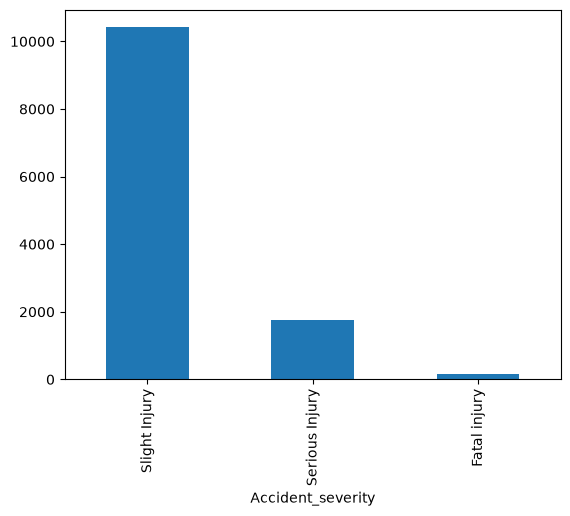

In [5]:
print(df['Accident_severity'].value_counts())
df['Accident_severity'].value_counts().plot(kind='bar')

<Axes: xlabel='Educational_level'>

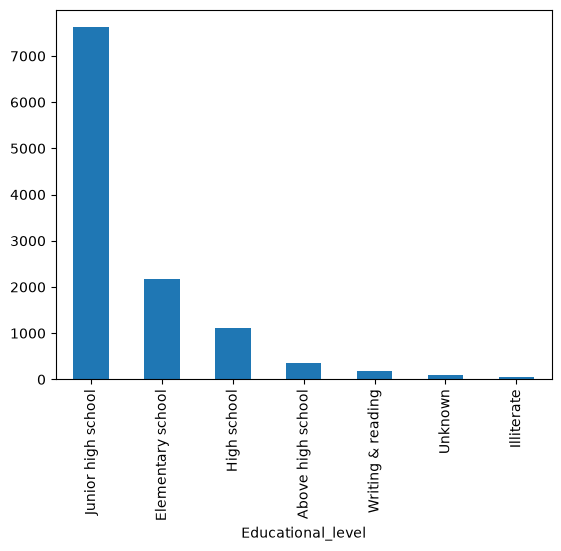

In [6]:
df['Educational_level'].value_counts().plot(kind='bar')

c:\Users\nober\AppData\Local\Programs\Python\Python313\Lib\site-packages\dabl\preprocessing.py:177: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  pd.to_datetime(series[:10])
c:\Users\nober\AppData\Local\Programs\Python\Python313\Lib\site-packages\dabl\preprocessing.py:182: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  pd.to_datetime(series)
c:\Users\nober\AppData\Local\Programs\Python\Python313\Lib\site-packages\dabl\preprocessing.py:177: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  pd.to_datetime(series[:10])
c:\Users\nober\AppData\Local\Programs\Python\Python313\Lib\site

Target looks like classification
Showing only top 10 of 31 categorical features


[<Axes: title={'center': 'Target distribution'}, xlabel='count', ylabel='Accident_severity'>,
 [array([[<Axes: xlabel='Number_of_casualties', ylabel='Number_of_casualties'>]],
        dtype=object)],
 array([[<Axes: title={'center': 'Number_of_vehicles_involved'}>,
         <Axes: title={'center': 'Types_of_Junction'}>,
         <Axes: title={'center': 'Age_band_of_driver'}>,
         <Axes: title={'center': 'Weather_conditions'}>,
         <Axes: title={'center': 'Type_of_vehicle'}>],
        [<Axes: title={'center': 'Area_accident_occured'}>,
         <Axes: title={'center': 'Cause_of_accident'}>,
         <Axes: title={'center': 'Day_of_week'}>,
         <Axes: title={'center': 'Light_conditions'}>,
         <Axes: title={'center': 'Type_of_collision'}>]], dtype=object)]

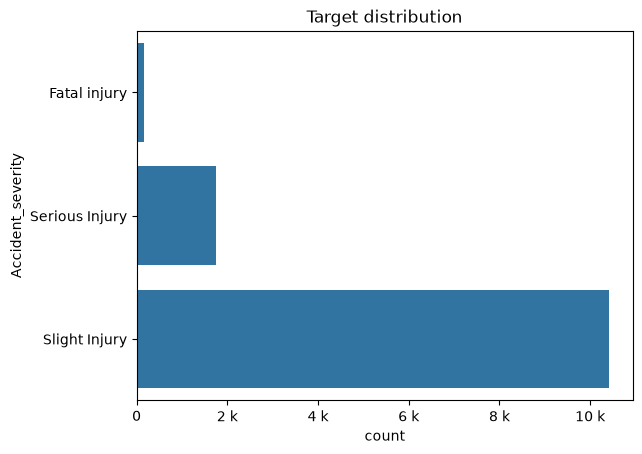

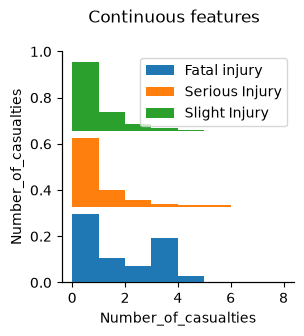

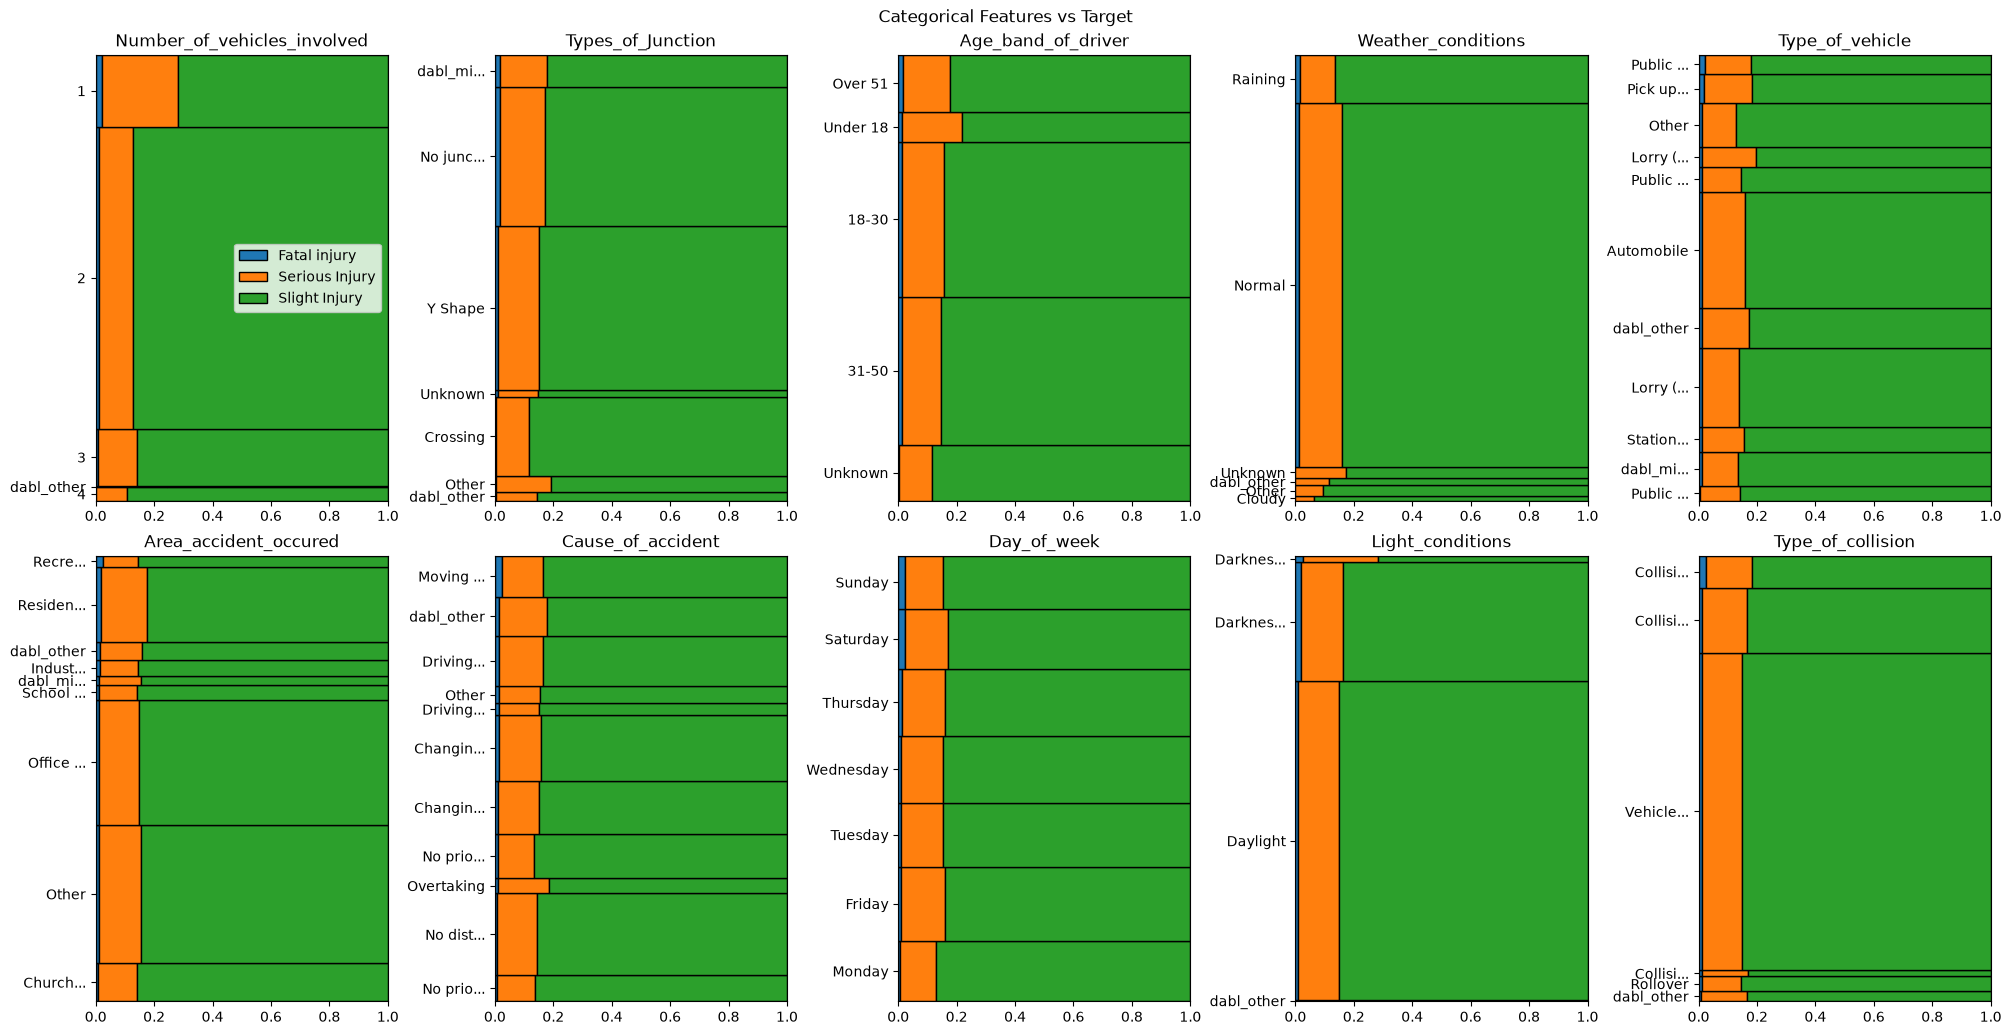

In [7]:
import dabl
dabl.plot(df, target_col='Accident_severity', figsize=(10, 6))

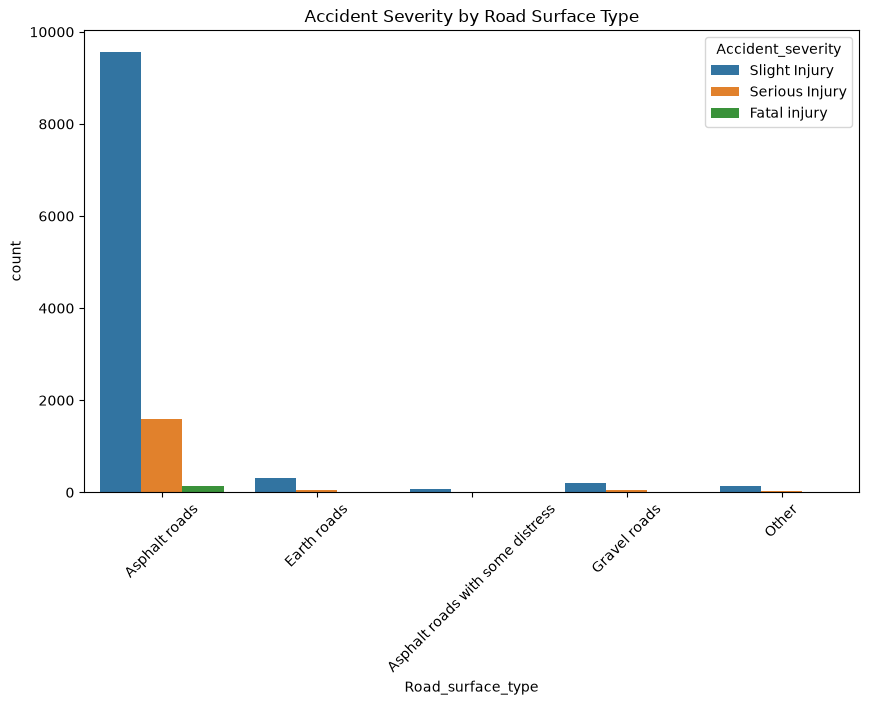

In [8]:
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.countplot(x='Road_surface_type', hue='Accident_severity', data=df)
plt.xticks(rotation=45)
plt.title('Accident Severity by Road Surface Type')
plt.show()

In [9]:
df['Time'] = pd.to_datetime(df['Time'])

new_df = df.copy()
new_df['Hour_of_Day'] = new_df['Time'].dt.hour
n_df = new_df.drop(['Time'], axis=1)
n_df.head()


C:\Users\nober\AppData\Local\Temp\ipykernel_10268\375457917.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Time'] = pd.to_datetime(df['Time'])


,Day_of_week,Age_band_of_driver,Sex_of_driver,Educational_level,Vehicle_driver_relation,Driving_experience,Type_of_vehicle,Owner_of_vehicle,Service_year_of_vehicle,Defect_of_vehicle,...,Casualty_class,Sex_of_casualty,Age_band_of_casualty,Casualty_severity,Work_of_casuality,Fitness_of_casuality,Pedestrian_movement,Cause_of_accident,Accident_severity,Hour_of_Day
0,Monday,18-30,Male,Above high school,Employee,1-2yr,Automobile,Owner,Above 10yr,No defect,...,na,na,na,na,NaN,NaN,Not a Pedestrian,Moving Backward,Slight Injury,17
1,Monday,31-50,Male,Junior high school,Employee,Above 10yr,Public (> 45 seats),Owner,5-10yrs,No defect,...,na,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury,17
2,Monday,18-30,Male,Junior high school,Employee,1-2yr,Lorry (41?100Q),Owner,NaN,No defect,...,Driver or rider,Male,31-50,3,Driver,NaN,Not a Pedestrian,Changing lane to the left,Serious Injury,17
3,Sunday,18-30,Male,Junior high school,Employee,5-10yr,Public (> 45 seats),Governmental,NaN,No defect,...,Pedestrian,Female,18-30,3,Driver,Normal,Not a Pedestrian,Changing lane to the right,Slight Injury,1
4,Sunday,18-30,Male,Junior high school,Employee,2-5yr,NaN,Owner,5-10yrs,No defect,...,na,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury,1


In [10]:
features = ['Day_of_week', 'Number_of_vehicles_involved', 'Number_of_casualties', 'Area_accident_occured', 'Types_of_Junction', 'Age_band_of_driver', 'Sex_of_driver', 'Educational_level', 'Vehicle_driver_relation', 'Type_of_vehicle', 'Driving_experience', 'Service_year_of_vehicle', 'Type_of_collision', 'Sex_of_casualty', 'Age_band_of_casualty', 'Cause_of_accident', 'Hour_of_Day']
len(features)

17

In [11]:
featureset_df = n_df[features]
target = n_df['Accident_severity']

In [12]:
featureset_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12316 entries, 0 to 12315
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   Day_of_week                  12316 non-null  str  
 1   Number_of_vehicles_involved  12316 non-null  int64
 2   Number_of_casualties         12316 non-null  int64
 3   Area_accident_occured        12077 non-null  str  
 4   Types_of_Junction            11429 non-null  str  
 5   Age_band_of_driver           12316 non-null  str  
 6   Sex_of_driver                12316 non-null  str  
 7   Educational_level            11575 non-null  str  
 8   Vehicle_driver_relation      11737 non-null  str  
 9   Type_of_vehicle              11366 non-null  str  
 10  Driving_experience           11487 non-null  str  
 11  Service_year_of_vehicle      8388 non-null   str  
 12  Type_of_collision            12161 non-null  str  
 13  Sex_of_casualty              12316 non-null  str  
 14  A

In [13]:
featureset_df.isnull().sum()

Day_of_week                       0
Number_of_vehicles_involved       0
Number_of_casualties              0
Area_accident_occured           239
Types_of_Junction               887
Age_band_of_driver                0
Sex_of_driver                     0
Educational_level               741
Vehicle_driver_relation         579
Type_of_vehicle                 950
Driving_experience              829
Service_year_of_vehicle        3928
Type_of_collision               155
Sex_of_casualty                   0
Age_band_of_casualty              0
Cause_of_accident                 0
Hour_of_Day                       0
dtype: int64

In [14]:
feature_df = featureset_df.copy()

feature_df['Service_year_of_vehicle'] = feature_df['Service_year_of_vehicle'].fillna('Unknown')
feature_df['Types_of_Junction'] = feature_df['Types_of_Junction'].fillna('Unknown')
feature_df['Area_accident_occured'] = feature_df['Area_accident_occured'].fillna('Unknown')
feature_df['Educational_level'] = feature_df['Educational_level'].fillna('Unknown')
feature_df['Vehicle_driver_relation'] = feature_df['Vehicle_driver_relation'].fillna('Unknown')
feature_df['Type_of_vehicle'] = feature_df['Type_of_vehicle'].fillna('Unknown')
feature_df['Driving_experience'] = feature_df['Driving_experience'].fillna('Unknown')
feature_df['Type_of_collision'] = feature_df['Type_of_collision'].fillna('Unknown')

feature_df.isnull().sum()

Day_of_week                    0
Number_of_vehicles_involved    0
Number_of_casualties           0
Area_accident_occured          0
Types_of_Junction              0
Age_band_of_driver             0
Sex_of_driver                  0
Educational_level              0
Vehicle_driver_relation        0
Type_of_vehicle                0
Driving_experience             0
Service_year_of_vehicle        0
Type_of_collision              0
Sex_of_casualty                0
Age_band_of_casualty           0
Cause_of_accident              0
Hour_of_Day                    0
dtype: int64

In [15]:
x = feature_df[features]
y = n_df['Accident_severity']

encoded_df = pd.get_dummies(x, drop_first=True)
encoded_df.shape

(12316, 108)

In [16]:
from sklearn.preprocessing import LabelEncoder

lb = LabelEncoder()
lb.fit(y)
y_encoded = lb.transform(y)
print('Encorded labels', lb.classes_)
y_en = pd.Series(y_encoded)

Encorded labels ['Fatal injury' 'Serious Injury' 'Slight Injury']


In [17]:
from sklearn.feature_selection import SelectKBest, chi2
fs = SelectKBest(chi2, k=50)
x_new = fs.fit_transform(encoded_df, y_en)

cols = fs.get_feature_names_out()
fs_df = pd.DataFrame(x_new, columns=cols)

In [18]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
x_n, y_n = smote.fit_resample(fs_df, y_en)

x_n.shape, y_n.shape

((31245, 50), (31245,))

In [19]:
print(y_n.value_counts())

2    10415
1    10415
0    10415
Name: count, dtype: int64


In [20]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

x_trn, x_tst, y_trn, y_tst = train_test_split(x_n, y_n, test_size=0.2, random_state=42)

rf = RandomForestClassifier(n_estimators=800, max_depth=20, random_state=42)
rf.fit(x_trn, y_trn)

predics = rf.predict(x_tst)

rf.score(x_trn, y_trn)

0.9403104496719475

In [21]:
calssif_re = classification_report(y_tst, predics)
print(calssif_re)

              precision    recall  f1-score   support

           0       0.93      0.96      0.94      2085
           1       0.81      0.83      0.82      2100
           2       0.87      0.82      0.84      2064

    accuracy                           0.87      6249
   macro avg       0.87      0.87      0.87      6249
weighted avg       0.87      0.87      0.87      6249



In [22]:
from sklearn.metrics import f1_score

f1score = f1_score(y_tst, predics, average='weighted')
print(f1score)

0.869536069942107


In [23]:
import joblib
from sklearn.preprocessing import OrdinalEncoder

new_fea_df = feature_df[['Type_of_collision', 'Age_band_of_driver', 'Sex_of_driver', 'Educational_level', 'Service_year_of_vehicle', 'Day_of_week', 'Area_accident_occured']] 
oencoder2 = OrdinalEncoder()
encoded_df3 = pd.DataFrame(oencoder2.fit_transform(new_fea_df))
encoded_df3.columns = new_fea_df.columns

joblib.dump(oencoder2, 'ordinal_encoder2.joblib')

['ordinal_encoder2.joblib']

In [25]:
s_final_df = pd.concat([feature_df[['Number_of_vehicles_involved', 'Number_of_casualties', 'Hour_of_Day']],encoded_df3], axis=1)

X_trn2, X_tst2, y_trn2, y_tst2 = train_test_split(s_final_df, y_en, test_size=0.2, random_state=42)

rf = RandomForestClassifier(n_estimators=700, max_depth=20, random_state=42)
rf.fit(X_trn2, y_trn2)

joblib.dump(rf, 'rf_model.joblib', compress=9)

['rf_model.joblib']